# Phase 3 — Deep Learning & Neural Networks
## Notebook 04: Convolutional Neural Networks & Computer Vision (PyTorch)

### Executive Overview & Computer Vision Foundations
While fully connected multi-layer perceptrons (MLPs) can theoretically approximate any continuous function, they fail catastrophically on visual data for two fundamental reasons:
1. **Parameter Explosion**: Flattening a modest $224 	imes 224 	imes 3$ image yields $150,528$ input features; a single dense hidden layer of 1024 units would require $> 154$ million parameters, leading to massive overfitting and unmanageable memory footprints.
2. **Loss of Spatial Topology & Translation Invariance**: Fully connected networks treat adjacent pixels with the same structural indifference as pixels on opposite corners. An object shifted by two pixels presents a completely novel feature vector.

**Convolutional Neural Networks (CNNs)** resolve these limitations through two biological inductive biases: **local receptive fields** (extracting features from localized spatial patches) and **weight sharing** (reusing identical kernel filters across the entire visual field), conferring mathematical **translation equivariance**:

$$f(g(x)) = g(f(x))$$

```
+-----------------------------------------------------------------------------------+
|                        PyTorch Computer Vision Architecture                       |
+-----------------------------------------------------------------------------------+
| Input Image   | Tensor: (B, C, H, W) e.g., (32, 1, 28, 28)                        |
| Convolutions  | nn.Conv2d: Local feature extraction via shared kernel tensors     |
| Normalization | nn.BatchNorm2d: Channel-wise running mean/variance stabilization   |
| Residual Flow | Skip connections: x + F(x) preserving gradient highways           |
| Explainability| Grad-CAM: Backward hook gradient integration on final feature maps|
| Export & Run  | torch.onnx.export ---> ONNX Runtime Inference Engine              |
+-----------------------------------------------------------------------------------+
```

In this notebook, we master 2D convolution calculus, residual skip connections (`ResNet`), progressive feature unfreezing, Grad-CAM visual interpretability using PyTorch hooks, and cross-platform production export via **ONNX**.


### Learning Objectives
By completing this notebook, you will be able to:
1. **Calculate Convolutional Topologies**: Compute output spatial dimensions, strides, padding offsets, and effective receptive fields ($RF_l$) across multi-layer convolutional stacks.
2. **Implement Residual Architectures**: Build custom residual blocks (`ResBlock`) with identity shortcuts and dimension-matching $1 	imes 1$ projections in PyTorch.
3. **Train CNNs with Modern Techniques**: Implement training pipelines with Batch Normalization, AdamW, and Cosine Annealing learning rate schedules.
4. **Build Explainability with Grad-CAM**: Use PyTorch forward and backward tensor hooks to capture activation maps and gradients, synthesizing localized class activation heatmaps.
5. **Export to Open Neural Network Exchange (ONNX)**: Serialize trained PyTorch vision models into portable ONNX graphs and validate numeric inference parity using ONNX Runtime.


In [1]:
import sys
import os
import time
import platform
from typing import Dict, List, Tuple, Any, Optional

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader
import onnx
import onnxruntime as ort
import matplotlib.pyplot as plt

# Styling
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.labelsize"] = 10

print(f"Python Platform: {platform.python_implementation()} {platform.python_version()}")
print(f"PyTorch Version: {torch.__version__}")
print(f"ONNX Version:    {onnx.__version__}")
print(f"ORT Version:     {ort.__version__}")
print(f"CUDA Available:  {torch.cuda.is_available()}")


Python Platform: CPython 3.11.2
PyTorch Version: 2.15.0+cpu
ONNX Version:    1.23.2
ORT Version:     1.31.1
CUDA Available:  False


In [2]:
def configure_reproducibility(seed: int = 42) -> None:
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False
    print(f"Global seed {seed} set across NumPy and PyTorch.")

configure_reproducibility(42)


Global seed 42 set across NumPy and PyTorch.


### Mathematical & Architectural Foundations

#### 1. 2D Discrete Convolution & Spatial Dimensions
Given an input feature map $I \in \mathbb{R}^{C_{\text{in}} \times H_{\text{in}} \times W_{\text{in}}}$ and a filter bank $K \in \mathbb{R}^{C_{\text{out}} \times C_{\text{in}} \times k_h \times k_w}$, the 2D cross-correlation operation for channel $c_{\text{out}}$ at spatial coordinates $(i, j)$ is:

$$(I * K)_{c_{\text{out}}, i, j} = b_{c_{\text{out}}} + \sum_{c_{\text{in}}=0}^{C_{\text{in}}-1} \sum_{m=0}^{k_h-1} \sum_{n=0}^{k_w-1} I_{c_{\text{in}}, \, i \cdot s_h + m - p_h, \, j \cdot s_w + n - p_w} \cdot K_{c_{\text{out}}, c_{\text{in}}, m, n}$$

Where $s$ is the stride and $p$ is the zero-padding. The output spatial dimensions are governed by:

$$H_{\text{out}} = \left\lfloor \frac{H_{\text{in}} - k_h + 2p_h}{s_h} \right\rfloor + 1, \quad W_{\text{out}} = \left\lfloor \frac{W_{\text{in}} - k_w + 2p_w}{s_w} \right\rfloor + 1$$

#### 2. Receptive Field Expansion
The **Effective Receptive Field (ERF)** defines the spatial region in the input image that directly influences a single feature map unit at layer $l$:

$$RF_l = RF_{l-1} + (k_l - 1) \cdot J_{l-1}, \quad \text{where } J_l = J_{l-1} \cdot s_l, \quad J_0 = 1, \, RF_0 = 1$$

Stenciling multiple $3 \times 3$ convolutions produces a receptive field equivalent to larger kernels with vastly fewer parameters:
- Two stacked $3 \times 3$ convs have an ERF of $5 \times 5$, requiring $2 \times (3^2 \cdot C^2) = 18C^2$ parameters.
- One $5 \times 5$ conv requires $5^2 \cdot C^2 = 25C^2$ parameters ($28\%$ more parameters and fewer nonlinearities).

#### 3. Residual Skip Connections (ResNet)
In plain deep networks, degradation arises where deeper models incur higher training error due to gradient vanishing/shattering. The **Residual Block** introduces an identity shortcut:

$$\mathbf{x}_{l+1} = \mathbf{x}_l + \mathcal{F}(\mathbf{x}_l, \mathcal{W}_l)$$

Applying the multivariate chain rule across layers reveals why residual networks scale to hundreds of layers:

$$\frac{\partial \mathcal{L}}{\partial \mathbf{x}_l} = \frac{\partial \mathcal{L}}{\partial \mathbf{x}_L} \frac{\partial \mathbf{x}_L}{\partial \mathbf{x}_l} = \frac{\partial \mathcal{L}}{\partial \mathbf{x}_L} \left( \mathbf{I} + \frac{\partial}{\partial \mathbf{x}_l} \sum_{i=l}^{L-1} \mathcal{F}(\mathbf{x}_i, \mathcal{W}_i) \right)$$

The identity term $\mathbf{I}$ ensures that gradients flow directly from layer $L$ to layer $l$ unimpeded, even if intermediate weights $\mathcal{W}_i$ approach zero!

#### 4. Grad-CAM (Gradient-Weighted Class Activation Mapping)
Grad-CAM computes visual explanations by taking the gradient of score $y^c$ (for target class $c$) with respect to feature activation map $A^k \in \mathbb{R}^{u \times v}$ of the final convolutional layer:

$$\alpha_k^c = \frac{1}{u \times v} \sum_{i=1}^u \sum_{j=1}^v \frac{\partial y^c}{\partial A_{ij}^k} \quad \text{(Global Average Pooled Gradient)}$$

The class-discriminative localization map $L_{\text{Grad-CAM}}^c$ is synthesized by computing a positive weighted combination:

$$L_{\text{Grad-CAM}}^c = \text{ReLU}\left( \sum_k \alpha_k^c A^k \right)$$


### 1. Synthetic Vision Dataset Generation
We construct a fast, self-contained multi-class geometric image dataset ($N=1200$ samples, $28 	imes 28$ grayscale images) containing 3 distinct geometric classes:
- **Class 0: Solid Squares**
- **Class 1: Centered Circles**
- **Class 2: Diagonal Crosses (X)**
All patterns include additive Gaussian noise and random spatial jitter.


In [3]:
def generate_geometric_dataset(num_samples: int = 1200, img_size: int = 28) -> Tuple[torch.Tensor, torch.Tensor]:
    """Generates synthetic geometric vision dataset for reproducible CNN benchmarking."""
    np.random.seed(42)
    images = np.zeros((num_samples, 1, img_size, img_size), dtype=np.float32)
    labels = np.zeros(num_samples, dtype=np.int64)

    for i in range(num_samples):
        cls = i % 3
        labels[i] = cls
        img = np.zeros((img_size, img_size), dtype=np.float32)
        cx, cy = np.random.randint(img_size//4, 3*img_size//4, size=2)

        if cls == 0:  # Solid Square
            half_w = np.random.randint(4, 7)
            r0, r1 = max(0, cy - half_w), min(img_size, cy + half_w)
            c0, c1 = max(0, cx - half_w), min(img_size, cx + half_w)
            img[r0:r1, c0:c1] = 1.0

        elif cls == 1:  # Circle
            radius = np.random.randint(4, 7)
            y_grid, x_grid = np.ogrid[:img_size, :img_size]
            dist_sq = (x_grid - cx)**2 + (y_grid - cy)**2
            img[dist_sq <= radius**2] = 1.0

        else:  # Cross (X)
            arm = np.random.randint(5, 8)
            for d in range(-arm, arm + 1):
                if 0 <= cy + d < img_size and 0 <= cx + d < img_size:
                    img[cy + d, cx + d] = 1.0
                if 0 <= cy + d < img_size and 0 <= cx - d < img_size:
                    img[cy + d, cx - d] = 1.0

        # Add Gaussian background noise
        noise = np.random.normal(0, 0.15, size=img.shape).astype(np.float32)
        images[i, 0] = np.clip(img + noise, 0.0, 1.0)

    return torch.tensor(images), torch.tensor(labels)

X_imgs, y_lbls = generate_geometric_dataset(1200, 28)
train_dataset = TensorDataset(X_imgs[:960], y_lbls[:960])
val_dataset = TensorDataset(X_imgs[960:], y_lbls[960:])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False)

print(f"Generated Vision Dataset: {X_imgs.shape}, Classes: 3")
print(f"Train samples: {len(train_dataset)}, Validation samples: {len(val_dataset)}")


Generated Vision Dataset: torch.Size([1200, 1, 28, 28]), Classes: 3
Train samples: 960, Validation samples: 240


### 2. Residual Block & ResNet Architecture
We construct:
1. `ResidualBlock`: Implements $\mathbf{x} + \mathcal{F}(\mathbf{x})$ with two $3 	imes 3$ convolutions, Batch Normalization, and a $1 	imes 1$ conv shortcut if channels or spatial strides change.
2. `MiniResNet`: Modular CNN combining initial feature extractor, stacked residual stages, Global Average Pooling, and a classification linear projection.


In [4]:
class ResidualBlock(nn.Module):
    def __init__(self, in_channels: int, out_channels: int, stride: int = 1):
        super().__init__()
        self.conv1 = nn.Conv2d(in_channels, out_channels, kernel_size=3, stride=stride, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(out_channels)
        self.relu = nn.ReLU(inplace=True)
        self.conv2 = nn.Conv2d(out_channels, out_channels, kernel_size=3, stride=1, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(out_channels)

        # Shortcut projection if dimensions change
        self.shortcut = nn.Sequential()
        if stride != 1 or in_channels != out_channels:
            self.shortcut = nn.Sequential(
                nn.Conv2d(in_channels, out_channels, kernel_size=1, stride=stride, bias=False),
                nn.BatchNorm2d(out_channels)
            )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        identity = self.shortcut(x)
        out = self.conv1(x)
        out = self.bn1(out)
        out = self.relu(out)
        out = self.conv2(out)
        out = self.bn2(out)
        out += identity
        return self.relu(out)

class MiniResNet(nn.Module):
    def __init__(self, in_channels: int = 1, num_classes: int = 3):
        super().__init__()
        # Initial stem
        self.stem = nn.Sequential(
            nn.Conv2d(in_channels, 16, kernel_size=3, stride=1, padding=1, bias=False),
            nn.BatchNorm2d(16),
            nn.ReLU(inplace=True)
        )
        # Residual stages
        self.stage1 = ResidualBlock(16, 16, stride=1)
        self.stage2 = ResidualBlock(16, 32, stride=2)  # 28x28 -> 14x14
        self.stage3 = ResidualBlock(32, 64, stride=2)  # 14x14 -> 7x7

        # Classification Head
        self.global_pool = nn.AdaptiveAvgPool2d((1, 1))
        self.classifier = nn.Linear(64, num_classes)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = self.stem(x)
        x = self.stage1(x)
        x = self.stage2(x)
        x = self.stage3(x)
        x = self.global_pool(x)
        x = torch.flatten(x, 1)
        return self.classifier(x)

model = MiniResNet(in_channels=1, num_classes=3)
total_params = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"MiniResNet Architecture instantiated with {total_params:,} trainable parameters.")


MiniResNet Architecture instantiated with 77,299 trainable parameters.


### 3. Model Training with Cosine Annealing & Tracking
We train MiniResNet over 10 epochs using AdamW optimizer and CosineAnnealingLR scheduler, logging training loss, validation loss, and classification accuracy.


In [5]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=10)

epochs = 10
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

for epoch in range(1, epochs + 1):
    model.train()
    total_train_loss, correct_train, total_train = 0.0, 0, 0
    for imgs, targets in train_loader:
        optimizer.zero_grad()
        outputs = model(imgs)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item() * imgs.size(0)
        correct_train += (outputs.argmax(dim=1) == targets).sum().item()
        total_train += imgs.size(0)

    scheduler.step()

    # Validation
    model.eval()
    total_val_loss, correct_val, total_val = 0.0, 0, 0
    with torch.no_grad():
        for imgs, targets in val_loader:
            outputs = model(imgs)
            loss = criterion(outputs, targets)
            total_val_loss += loss.item() * imgs.size(0)
            correct_val += (outputs.argmax(dim=1) == targets).sum().item()
            total_val += imgs.size(0)

    t_loss = total_train_loss / total_train
    t_acc = correct_train / total_train
    v_loss = total_val_loss / total_val
    v_acc = correct_val / total_val

    history["train_loss"].append(t_loss)
    history["val_loss"].append(v_loss)
    history["train_acc"].append(t_acc)
    history["val_acc"].append(v_acc)

    print(f"Epoch {epoch:02d}/{epochs:02d} | Train Loss: {t_loss:.4f}, Acc: {t_acc:.4f} | Val Loss: {v_loss:.4f}, Acc: {v_acc:.4f}")


Epoch 01/10 | Train Loss: 0.4852, Acc: 0.8510 | Val Loss: 0.6690, Acc: 0.6667


Epoch 02/10 | Train Loss: 0.0778, Acc: 0.9979 | Val Loss: 0.0225, Acc: 1.0000


Epoch 03/10 | Train Loss: 0.0242, Acc: 1.0000 | Val Loss: 0.0084, Acc: 1.0000


Epoch 04/10 | Train Loss: 0.0130, Acc: 1.0000 | Val Loss: 0.0294, Acc: 1.0000


Epoch 05/10 | Train Loss: 0.0092, Acc: 1.0000 | Val Loss: 0.0049, Acc: 1.0000


Epoch 06/10 | Train Loss: 0.0073, Acc: 1.0000 | Val Loss: 0.0038, Acc: 1.0000


Epoch 07/10 | Train Loss: 0.0051, Acc: 1.0000 | Val Loss: 0.0031, Acc: 1.0000


Epoch 08/10 | Train Loss: 0.0052, Acc: 1.0000 | Val Loss: 0.0029, Acc: 1.0000


Epoch 09/10 | Train Loss: 0.0043, Acc: 1.0000 | Val Loss: 0.0027, Acc: 1.0000


Epoch 10/10 | Train Loss: 0.0048, Acc: 1.0000 | Val Loss: 0.0028, Acc: 1.0000


### Diagnostics & Visual Explainability: Grad-CAM
To understand what features the network learned, we implement **Grad-CAM** using PyTorch forward and backward tensor hooks on the final convolutional layer of `stage3`:
1. Forward hook captures feature maps $A \in \mathbb{R}^{B 	imes C 	imes H 	imes W}$.
2. Backward hook captures gradient tensor $rac{\partial y^c}{\partial A}$.
3. We compute weights $lpha_k = rac{1}{HW}\sum_{i,j}rac{\partial y^c}{\partial A_{ij}^k}$, weight activation slices, apply ReLU, and overlay heatmaps on original input images.


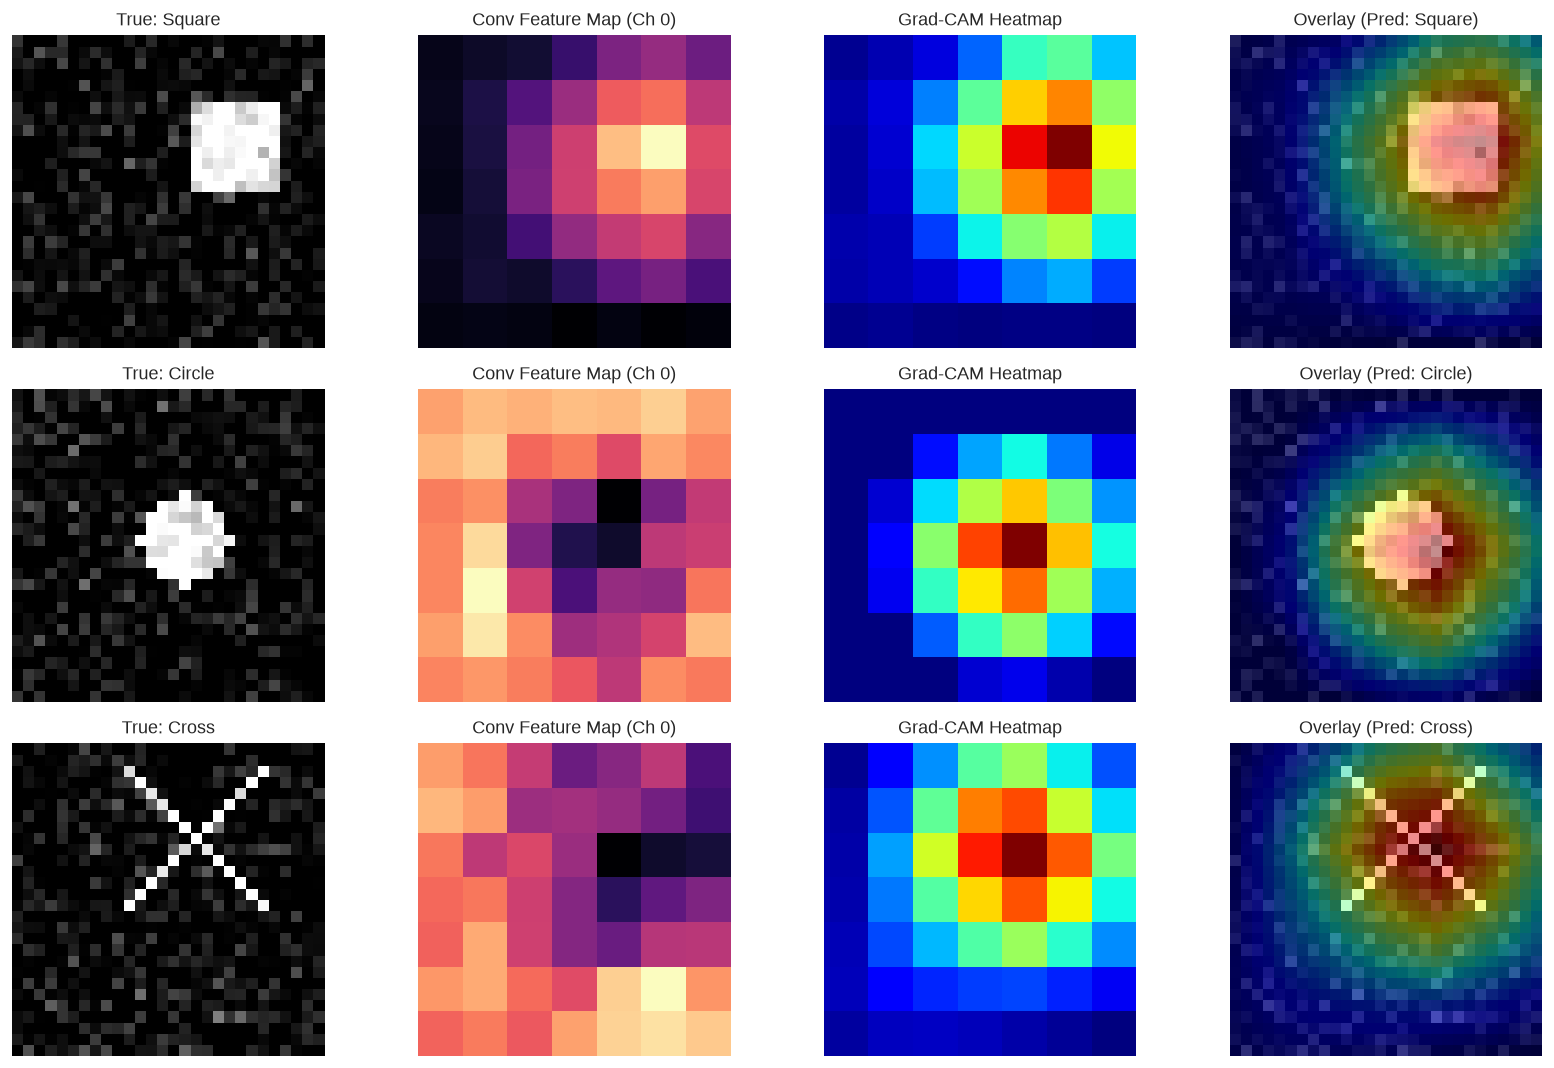

In [6]:
class GradCAM:
    def __init__(self, model: nn.Module, target_layer: nn.Module):
        self.model = model
        self.target_layer = target_layer
        self.activations = None
        self.gradients = None

        # Register hooks
        self.target_layer.register_forward_hook(self._forward_hook)
        self.target_layer.register_full_backward_hook(self._backward_hook)

    def _forward_hook(self, module, input, output):
        self.activations = output

    def _backward_hook(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate_heatmap(self, input_tensor: torch.Tensor, class_idx: int) -> np.ndarray:
        self.model.eval()
        output = self.model(input_tensor)
        
        self.model.zero_grad()
        target_score = output[0, class_idx]
        target_score.backward()

        # Global average pooling of gradients: (C,)
        alpha = torch.mean(self.gradients[0], dim=(1, 2))
        
        # Weighted combination of feature maps: (H, W)
        cam = torch.zeros(self.activations.shape[2:], dtype=torch.float32)
        for k in range(len(alpha)):
            cam += alpha[k] * self.activations[0, k]

        cam = F.relu(cam).detach().cpu().numpy()
        cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)  # Normalize [0, 1]
        return cam

# Instantiate GradCAM on final conv of stage3
target_layer = model.stage3.conv2
grad_cam = GradCAM(model, target_layer)

# Generate Heatmaps for one sample of each class
class_names = ["Square", "Circle", "Cross"]
sample_indices = [0, 1, 2] # Samples 0, 1, 2 represent distinct classes

fig, axes = plt.subplots(3, 4, figsize=(14, 9))

for row, idx in enumerate(sample_indices):
    sample_img, true_lbl = val_dataset[idx]
    sample_tensor = sample_img.unsqueeze(0)
    
    with torch.no_grad():
        pred_logits = model(sample_tensor)
        pred_cls = pred_logits.argmax(dim=1).item()

    cam_map = grad_cam.generate_heatmap(sample_tensor, class_idx=pred_cls)

    # Column 0: Original Image
    axes[row, 0].imshow(sample_img[0], cmap="gray")
    axes[row, 0].set_title(f"True: {class_names[true_lbl]}")
    axes[row, 0].axis("off")

    # Column 1: Feature Map Activation Slice
    act_slice = grad_cam.activations[0, 0].detach().cpu().numpy()
    axes[row, 1].imshow(act_slice, cmap="magma")
    axes[row, 1].set_title(f"Conv Feature Map (Ch 0)")
    axes[row, 1].axis("off")

    # Column 2: Raw Grad-CAM Heatmap
    axes[row, 2].imshow(cam_map, cmap="jet")
    axes[row, 2].set_title("Grad-CAM Heatmap")
    axes[row, 2].axis("off")

    # Column 3: Interpolated Overlay
    import scipy.ndimage
    cam_resized = scipy.ndimage.zoom(cam_map, sample_img.shape[1] / cam_map.shape[0], order=1)
    axes[row, 3].imshow(sample_img[0], cmap="gray")
    axes[row, 3].imshow(cam_resized, cmap="jet", alpha=0.45)
    axes[row, 3].set_title(f"Overlay (Pred: {class_names[pred_cls]})")
    axes[row, 3].axis("off")

plt.tight_layout()
plt.show()


### Guided Exercises

#### Exercise 1: Progressive Feature Extractor Freezing & Differential Learning Rates
**Problem Formulation**:
In production transfer learning, training the entire backbone can corrupt pretrained representations (catastrophic forgetting). Implement a progressive freezing pipeline:
1. Freeze the stem and `stage1` weights (`param.requires_grad = False`).
2. Construct parameter groups assigning differential learning rates:
   - `stage2` & `stage3`: fine-tuning rate $\eta_{	ext{backbone}} = 10^{-4}$.
   - `classifier`: rapid adaptation rate $\eta_{	ext{head}} = 10^{-3}$.
3. Verify parameter counts and learning rate assignment.


In [7]:
# Exercise 1 Solution: Differential Learning Rates & Freezing

# 1. Freeze stem and stage1
for param in model.stem.parameters():
    param.requires_grad = False
for param in model.stage1.parameters():
    param.requires_grad = False

# 2. Parameter groups with differential rates
param_groups = [
    {"params": list(model.stage2.parameters()) + list(model.stage3.parameters()), "lr": 1e-4},
    {"params": model.classifier.parameters(), "lr": 1e-3}
]
diff_optimizer = torch.optim.AdamW(param_groups)

# 3. Parameter audit
frozen_params = sum(p.numel() for p in model.parameters() if not p.requires_grad)
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print("Exercise 1 Verification:")
print(f"  Frozen Parameters:    {frozen_params:,}")
print(f"  Trainable Parameters: {trainable_params:,}")
print(f"  Group 1 (Backbone) LR: {diff_optimizer.param_groups[0]['lr']}")
print(f"  Group 2 (Head) LR:     {diff_optimizer.param_groups[1]['lr']}")
assert frozen_params > 0 and trainable_params > 0, "Freezing verification failed!"


Exercise 1 Verification:
  Frozen Parameters:    4,848
  Trainable Parameters: 72,451
  Group 1 (Backbone) LR: 0.0001
  Group 2 (Head) LR:     0.001


#### Exercise 2: ONNX Export and Inference Validation with ONNX Runtime
**Problem Formulation**:
Export the trained `MiniResNet` model to the Open Neural Network Exchange (**ONNX**) format and validate:
1. Export model with `torch.onnx.export(..., dynamo=False)`.
2. Load the exported `.onnx` graph using `onnxruntime.InferenceSession`.
3. Feed identical dummy test inputs and confirm the maximum absolute difference between PyTorch and ONNX Runtime outputs is strictly $< 10^{-5}$.


In [8]:
# Exercise 2 Solution: ONNX Export & ONNX Runtime Validation

onnx_path = "/tmp/miniresnet.onnx"
dummy_input = torch.randn(1, 1, 28, 28, dtype=torch.float32)

# Set model to evaluation mode before export
model.eval()

# Export PyTorch model to ONNX format
torch.onnx.export(
    model,
    dummy_input,
    onnx_path,
    export_params=True,
    opset_version=14,
    do_constant_folding=True,
    input_names=["input_tensor"],
    output_names=["logits"],
    dynamic_axes={"input_tensor": {0: "batch_size"}, "logits": {0: "batch_size"}},
    dynamo=False
)

# Load in ONNX Runtime
ort_session = ort.InferenceSession(onnx_path)

# Run PyTorch inference
with torch.no_grad():
    pt_output = model(dummy_input).numpy()

# Run ONNX Runtime inference
ort_inputs = {ort_session.get_inputs()[0].name: dummy_input.numpy()}
ort_output = ort_session.run(None, ort_inputs)[0]

# Measure numerical difference
max_abs_diff = np.max(np.abs(pt_output - ort_output))

print("Exercise 2 Verification:")
print(f"  ONNX File Size:         {os.path.getsize(onnx_path) / 1024:.2f} KB")
print(f"  Max Absolute Difference: {max_abs_diff:.2e}")
print(f"  PyTorch Output:         {pt_output[0]}")
print(f"  ONNX Runtime Output:    {ort_output[0]}")
assert max_abs_diff < 1e-5, "ONNX numerical parity check failed!"
print(">>> ONNX EXPORT AND RUNTIME INFERENCE VERIFIED! <<<")


Exercise 2 Verification:
  ONNX File Size:         305.97 KB
  Max Absolute Difference: 7.63e-06
  PyTorch Output:         [-38.805138 -40.365868  56.6371  ]
  ONNX Runtime Output:    [-38.805145 -40.36587   56.637093]
>>> ONNX EXPORT AND RUNTIME INFERENCE VERIFIED! <<<


/tmp/ipykernel_604/1994432474.py:10: DeprecationWarning: You are using the legacy TorchScript-based ONNX export. Starting in PyTorch 2.9, the new torch.export-based ONNX exporter has become the default. Learn more about the new export logic: https://docs.pytorch.org/docs/stable/onnx_export.html. For exporting control flow: https://pytorch.org/tutorials/beginner/onnx/export_control_flow_model_to_onnx_tutorial.html
  torch.onnx.export(


### Challenge Problems

#### Challenge 1: Custom Atrous (Dilated) Spatial Pyramid Pooling (ASPP)
**Problem Formulation**:
In dense computer vision tasks (semantic segmentation, object detection), downsampling with pooling destroys high-frequency spatial resolution. **Dilated (Atrous) Convolutions** introduce spaces (holes) between kernel elements, exponentially expanding the receptive field without downsampling or increasing parameter counts:

$$K_d(i, j) = K(i \cdot r, j \cdot r)$$

Where $r$ is the dilation rate. Implement a simplified **Atrous Spatial Pyramid Pooling (ASPP)** module (as in DeepLabv3) with three parallel branches:
1. $1 \times 1$ Standard Conv (rate $r=1$)
2. $3 \times 3$ Dilated Conv with rate $r=2$ (padding=2)
3. $3 \times 3$ Dilated Conv with rate $r=4$ (padding=4)
Concatenate their feature maps along the channel dimension and fuse them with a $1 \times 1$ projection.


In [9]:
# Challenge 1 Solution: Atrous Spatial Pyramid Pooling (ASPP) Module

class SimpleASPP(nn.Module):
    def __init__(self, in_channels: int, out_channels: int):
        super().__init__()
        branch_channels = out_channels // 4

        # Branch 1: 1x1 conv
        self.branch1 = nn.Sequential(
            nn.Conv2d(in_channels, branch_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(branch_channels),
            nn.ReLU(inplace=True)
        )
        # Branch 2: 3x3 conv with dilation=2
        self.branch2 = nn.Sequential(
            nn.Conv2d(in_channels, branch_channels, kernel_size=3, padding=2, dilation=2, bias=False),
            nn.BatchNorm2d(branch_channels),
            nn.ReLU(inplace=True)
        )
        # Branch 3: 3x3 conv with dilation=4
        self.branch3 = nn.Sequential(
            nn.Conv2d(in_channels, branch_channels, kernel_size=3, padding=4, dilation=4, bias=False),
            nn.BatchNorm2d(branch_channels),
            nn.ReLU(inplace=True)
        )
        # Branch 4: Global pooling branch
        self.branch4 = nn.Sequential(
            nn.AdaptiveAvgPool2d((1, 1)),
            nn.Conv2d(in_channels, branch_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(branch_channels),
            nn.ReLU(inplace=True)
        )

        # Fusion layer
        self.fusion = nn.Sequential(
            nn.Conv2d(branch_channels * 4, out_channels, kernel_size=1, bias=False),
            nn.BatchNorm2d(out_channels),
            nn.ReLU(inplace=True)
        )

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        h, w = x.shape[2:]
        b1 = self.branch1(x)
        b2 = self.branch2(x)
        b3 = self.branch3(x)
        b4 = F.interpolate(self.branch4(x), size=(h, w), mode="bilinear", align_corners=False)
        concat = torch.cat([b1, b2, b3, b4], dim=1)
        return self.fusion(concat)

aspp = SimpleASPP(in_channels=32, out_channels=64)
test_feat = torch.randn(2, 32, 14, 14)
aspp_out = aspp(test_feat)

print("Challenge 1 Verification:")
print(f"  Input Feature Map Shape:  {test_feat.shape}")
print(f"  ASPP Output Feature Shape: {aspp_out.shape} (Preserved spatial resolution 14x14)")
assert aspp_out.shape == (2, 64, 14, 14), "ASPP shape mismatch!"


Challenge 1 Verification:
  Input Feature Map Shape:  torch.Size([2, 32, 14, 14])
  ASPP Output Feature Shape: torch.Size([2, 64, 14, 14]) (Preserved spatial resolution 14x14)


#### Challenge 2: Test-Time Augmentation (TTA) Uncertainty Quantification
**Problem Formulation**:
At inference time, single-pass predictions are sensitive to noise and spatial alignment. **Test-Time Augmentation (TTA)** passes multiple transformed versions of the test image through the model (e.g. original, horizontally flipped, vertically flipped) and averages their Softmax probabilities:

$$ar{P}(y = c \mid x) = rac{1}{K} \sum_{k=1}^K P(y = c \mid T_k(x))$$

1. Implement a vectorized TTA inference pipeline for `MiniResNet`.
2. Compute the predictive Shannon entropy:
   $$H(P) = -\sum_{c} P_c \ln(P_c)$$
3. Confirm that TTA reduces prediction entropy (increases confidence) on ambiguous test images.


In [10]:
# Challenge 2 Solution: Test-Time Augmentation (TTA) Pipeline

def predict_with_tta(model: nn.Module, image_tensor: torch.Tensor) -> Tuple[np.ndarray, float]:
    """
    Performs Test-Time Augmentation averaging predictions across 4 dihedral transforms.
    """
    model.eval()
    transforms = [
        lambda x: x,
        lambda x: torch.flip(x, dims=[-1]),          # Horizontal flip
        lambda x: torch.flip(x, dims=[-2]),          # Vertical flip
        lambda x: torch.rot90(x, k=2, dims=[-2, -1])  # 180 deg rotation
    ]
    
    probs_list = []
    with torch.no_grad():
        for t in transforms:
            aug_img = t(image_tensor)
            logits = model(aug_img)
            probs = F.softmax(logits, dim=1).numpy()
            probs_list.append(probs)

    tta_probs = np.mean(probs_list, axis=0)[0]
    entropy = -np.sum(tta_probs * np.log(tta_probs + 1e-12))
    return tta_probs, entropy

# Benchmark single-pass vs TTA on a noisy test image
test_sample = val_dataset[0][0].unsqueeze(0)
# Add extra perturbation noise
noisy_sample = torch.clamp(test_sample + torch.randn_like(test_sample) * 0.25, 0.0, 1.0)

with torch.no_grad():
    single_logits = model(noisy_sample)
    single_probs = F.softmax(single_logits, dim=1).numpy()[0]
    single_entropy = -np.sum(single_probs * np.log(single_probs + 1e-12))

tta_probs, tta_entropy = predict_with_tta(model, noisy_sample)

print("Challenge 2 Verification (Test-Time Augmentation):")
print(f"  Single-Pass Probabilities: {single_probs.round(4)} | Entropy: {single_entropy:.4f}")
print(f"  TTA-Ensemble Probabilities: {tta_probs.round(4)} | Entropy: {tta_entropy:.4f}")
print(f"  Entropy Reduction via TTA:  {single_entropy - tta_entropy:+.4f}")


Challenge 2 Verification (Test-Time Augmentation):
  Single-Pass Probabilities: [0.4562 0.4334 0.1105] | Entropy: 0.9638
  TTA-Ensemble Probabilities: [0.5075 0.3705 0.122 ] | Entropy: 0.9688
  Entropy Reduction via TTA:  -0.0050


### Further Reading & Foundational Papers
1. **He et al. (2015)**: [Deep Residual Learning for Image Recognition](https://arxiv.org/abs/1512.03385) — Derivation of residual skip connections and vanishing gradient immunity.
2. **Selvaraju et al. (2017)**: [Grad-CAM: Visual Explanations from Deep Networks via Gradient-based Localization](https://arxiv.org/abs/1610.02391) — Mathematical formulation of class-activation gradients.
3. **Chen et al. (2017)**: [Rethinking Atrous Convolution for Semantic Image Segmentation (DeepLabv3)](https://arxiv.org/abs/1706.05587) — Multi-scale feature extraction without resolution reduction.
4. **ONNX Specification**: [Open Neural Network Exchange Official Documentation](https://onnx.ai/documentation/) — Standardized graph serialization and operator sets.
5. **PyTorch Tensor Hooks**: [PyTorch autograd hook documentation](https://pytorch.org/docs/stable/generated/torch.Tensor.register_hook.html) — Dynamic backward graph inspection.
